# 02 — Evaluatie en afstelling van het detectiemodel

Dit notebook behandelt alles wat **na** het trainen van ons detectiemodel gebeurde: hoe goed is het, is het beter dan
het standaard COCO-model, en met welke instellingen (beeldgrootte, confidence-drempel, NMS-IoU) halen we er het meeste
uit? Het trainen zelf (dataset, labels, trainingsrun) staat in **notebook 01** (`01_model_training.ipynb`); hoe de bal over de frames
gevolgd wordt (Kalman-filter, interpolatie, crop-herdetectie) staat in **notebook 04** (`04_tracking_en_balbezit.ipynb`);
de volledige evaluatie van het systeem (posities in meters, rollen, balbezit) in **notebook 06**
(`06_systeemevaluatie.ipynb`). Hier gebruiken we uit die evaluatie alleen de balmaten om instellingen te vergelijken.

De zware berekeningen (evaluatie met `val()`, een extra fine-tune, YOLO over de hele clip met verschillende instellingen)
draaiden op de GPU van een teamgenoot (RTX 4070 Laptop, 8 GB, 27 minuten). Dit notebook leest die resultaten in uit
`data/results/gpu_run/` en tekent alles zelf opnieuw. De pijplijn op de hele clip draait hier wel opnieuw, maar uit de
opgeslagen YOLO-detecties (cache): dat kost een paar seconden per instelling en geen GPU.

**Conclusie in het kort**

- Ons model is veel beter dan het COCO-basismodel: COCO vindt **geen enkele bal** op de testset (bal-AP50 0,000), ons
  model wel (0,195), en personen worden nauwkeuriger omkaderd (mAP50-95 0,815 tegenover 0,669). Die cijfers zijn wel
  te optimistisch: de testbeelden zaten in de trainingsdata (zie sectie 1).
- De NMS-IoU-drempel (0,3 tot 0,8) maakt voor ons model praktisch niets uit; we houden de standaard 0,7.
- De grootste winst kwam niet van extra training maar van **inferentie op 1280 pixels in plaats van 960**: op de
  ground-truth-frames vindt de pijplijn de bal in **19 van 21** frames in plaats van 16, en het aantal frames zonder bal in
  de hele clip daalt van **192 naar 161** (met baldrempel 0,2).
- Een extra fine-tune voor de bal mislukte (beste epoch 1 van 16) en werd niet in gebruik genomen.
- Gekozen standaard: het oorspronkelijke model (`models/psg_vs_inter_CV.pt`), `imgsz 1280`, baldrempel 0,2, NMS-IoU 0,7.

## 0. Opzet: bestanden, stijl en hulpfuncties

Alle paden zijn relatief tegenover `final_upload/notebooks/`. De code van de app (`final_upload/streamlit/`) wordt
geïmporteerd voor de pijplijn en de evaluatie tegen de ground truth, zodat het notebook exact dezelfde code gebruikt als
de Streamlit-app.

**Namen.** In de bestanden van de GPU-run heet ons model `best.pt` (zo heette het toen); in `final_upload/` is dat
hetzelfde bestand, hernoemd naar `models/psg_vs_inter_CV.pt`. In dit notebook heet het "ons model". De mislukte
bal-fine-tune heet `best_ball_ft.pt` ("bal-fine-tune").

In [1]:
import json
import re
import sys
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

UPLOAD = Path("..")                                   # the final_upload folder
RES = UPLOAD / "data" / "results" / "gpu_run"        # results of the GPU run (copied from the original run folder)
DATASETS = UPLOAD / "data" / "datasets"
sys.path.insert(0, str(UPLOAD / "streamlit"))

import core.pipeline as pipe                          # noqa: E402
from core.detection import DETECT_CONF, cache_path    # noqa: E402
from core.paths import CACHE_DIR, DEFAULT_WEIGHTS, MODELS_DIR, VIDEO  # noqa: E402
from core.tracking import BALL_START_CONF, BALL_WEAK, TRACK_LOW_THRESH  # noqa: E402
from evaluation.gt_format import load_gt               # noqa: E402
from evaluation.metrics import evaluate, load_predictions  # noqa: E402

FT_WEIGHTS = MODELS_DIR / "experimenten" / "best_ball_ft.pt"
LAST_FRAME = 659                                      # the clip has 660 frames (0..659)

# --- one plot style for the whole notebook --------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "legend.frameon": False, "lines.linewidth": 2,
})
# Fixed colour per model (Okabe-Ito, colour-blind friendly); the image size is shown with the line style.
MODEL_COLOR = {"COCO yolo26l": "#7a7a7a", "ons model": "#0072B2", "bal-fine-tune": "#D55E00"}
SIZE_STYLE = {960: "--", 1280: "-"}
# Fixed colour per class (PSG = team A = player_A, Inter = team B = player_B)
CLASS_COLOR = {"ball": "#E69F00", "player_A": "#56B4E9", "player_B": "#009E73",
               "player_B_goal_keeper": "#CC79A7", "referee": "#555555", "person": "#0072B2"}
CLASS_NL = {"ball": "bal", "player_A": "speler PSG (A)", "player_B": "speler Inter (B)",
            "player_B_goal_keeper": "keeper Inter", "referee": "scheidsrechter", "person": "persoon", "all": "alle"}
# Run names in the GPU-run files -> (model, imgsz)
RUNS = {"COCO_yolo26l": ("COCO yolo26l", 960), "bestpt": ("ons model", 960), "bestpt_1280": ("ons model", 1280),
        "ball-finetune": ("bal-fine-tune", 960), "ball-finetune_1280": ("bal-fine-tune", 1280)}
MODEL_OF_CSV = {"COCO yolo26l": "COCO yolo26l", "best.pt": "ons model", "best.pt@1280": "ons model",
                "ball-finetune": "bal-fine-tune", "ball-finetune@1280": "bal-fine-tune"}


def show(df, digits=3):
    # Display a DataFrame with a fixed number of decimals
    display(df.style.format(precision=digits, na_rep="–").hide(axis="index"))


env = json.loads((RES / "env.json").read_text(encoding="utf-8"))
print(f"GPU-run: {env['gpu']}, torch {env['torch']}, ultralytics {env['ultralytics']}, "
      f"klassen van ons model: {env['best_classes']}")

GPU-run: NVIDIA GeForce RTX 4070 Laptop GPU, torch 2.14.1+cu126, ultralytics 8.4.182, klassen van ons model: ['ball', 'player_A', 'player_B', 'player_B_goal_keeper', 'referee']


## 1. De vraag en de meetopzet

We willen twee dingen weten:

1. **Is ons model beter dan het COCO-basismodel?** Ons model is een YOLO26l die vertrok van de COCO-gewichten
   (getraind op 80 alledaagse klassen, waaronder `person` en `sports ball`) en daarna verder getraind werd op 136
   gelabelde frames van onze clip met 5 klassen: `ball`, `player_A` (PSG), `player_B` (Inter), `player_B_goal_keeper`
   en `referee` (zie notebook 01).
2. **Welke instellingen bij het detecteren zijn het best?** De beeldgrootte waarop YOLO het frame verwerkt
   (`imgsz`), de confidence-drempel per klasse, en de IoU-drempel van NMS (non-maximum suppression).

We meten op **twee niveaus**:

| Niveau | Wat | Data | Maat |
|---|---|---|---|
| A. Detectie | Elke box apart: is hij juist? | testset van 15 beelden (frames 600–658), 5 ballen en 326 personen, met boxen gelabeld | precision, recall, AP50, mAP50-95 (`val()` van ultralytics) |
| B. Hele pijplijn | Detectie + tracking + homografie + balbezit op de hele clip | 660 frames; ground truth = 22 frames waarop de eigenaar personen en bal aanklikte (`ground_truth.json`, lichaam) + 6 frames met voetklikken (`ground_truth_feet.json`) | bal gevonden, valse bal, frames zonder bal, juiste rol, balbezit |

Niveau A is de klassieke evaluatie van een detector (les over PR-curves en mAP). Niveau B is wat er voor de minimap
echt toe doet: een bal die de detector mist, kan de tracker soms nog invullen, en een valse bal kan de tracker
wegfilteren. Daarom beslissen we over instellingen uiteindelijk op niveau B.

### Eerlijke kanttekening: data leakage

*Data leakage* betekent dat informatie uit de testset in de training terechtkwam. Dan meet de test niet meer hoe goed
het model werkt op beelden die het nooit zag, maar deels hoe goed het zich zijn trainingsbeelden herinnert. De cel
hieronder vergelijkt de framenummers van de testset, de trainingsdata van ons model, de data van de bal-fine-tune en de
ground-truth-frames.

verzameling,beelden,overlap
trainingsdata van ons model (export v4),136,136 verschillende framenummers
oudere export v2 (basis van testset en fine-tune-data),100,100 van 100 in de trainingsdata
testset (GPU-run),15,15 van 15 zitten in de trainingsdata
fine-tune: train,59,59 van 59 in de trainingsdata; 0 in de testset
fine-tune: validatie,26,26 van 26 in de trainingsdata; 0 in de testset
ground truth (lichaam + voeten),22,"7 exact in de trainingsdata ([0, 30, 150, 210, 540, 570, 600]); 10 op ≤ 2 frames van een trainingsframe"


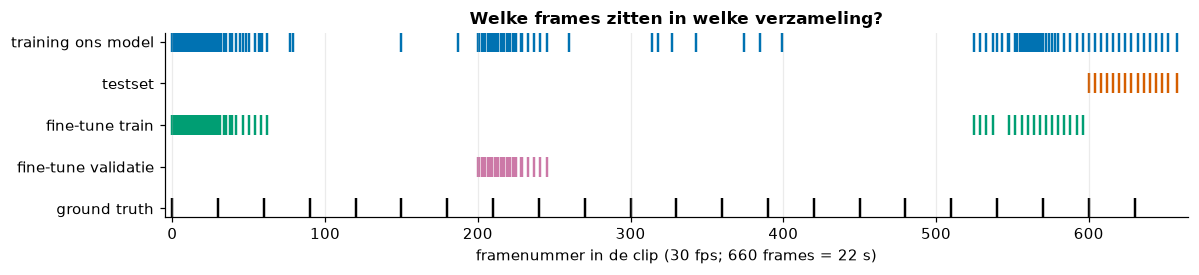

In [2]:
def frame_numbers(folder):
    # Frame numbers from Roboflow file names like frame_0600_idx_00600_jpg.rf.<hash>.jpg
    return sorted(int(re.search(r"frame_(\d+)", p.name).group(1)) for p in Path(folder).iterdir())


# The 136 training images of the final model (list from its ultralytics labels.cache, reconstructed in notebook 01)
train_files = [l.strip() for l in (RES / "final_model_train_files.txt").read_text().splitlines() if l.strip() and not l.startswith("#")]
train_ours = {int(re.search(r"frame_(\d+)", f).group(1)) for f in train_files}
v2 = set(frame_numbers(DATASETS / "roboflow_train" / "train" / "images"))           # older 100-image export (GPU-run base)
test = set(frame_numbers(DATASETS / "notebook_split" / "test" / "images"))           # test set of the GPU run
ft_train = set(frame_numbers(DATASETS / "ball_finetune" / "train" / "images"))
ft_val = set(frame_numbers(DATASETS / "ball_finetune" / "val" / "images"))
gt_body = load_gt(UPLOAD / "data" / "ground_truth.json")
gt_feet = load_gt(UPLOAD / "data" / "ground_truth_feet.json")
gt_frames = sorted(set(gt_body) | set(gt_feet))


def near(frames, ref, d=2):
    return sorted(f for f in frames if any(abs(f - r) <= d for r in ref))


rows = [
    ("trainingsdata van ons model (export v4)", len(train_files), f"{len(train_ours)} verschillende framenummers"),
    ("oudere export v2 (basis van testset en fine-tune-data)", len(v2), f"{len(v2 & train_ours)} van {len(v2)} in de trainingsdata"),
    ("testset (GPU-run)", len(test), f"{len(test & train_ours)} van {len(test)} zitten in de trainingsdata"),
    ("fine-tune: train", len(ft_train), f"{len(ft_train & train_ours)} van {len(ft_train)} in de trainingsdata; "
                                        f"{len(ft_train & test)} in de testset"),
    ("fine-tune: validatie", len(ft_val), f"{len(ft_val & train_ours)} van {len(ft_val)} in de trainingsdata; "
                                          f"{len(ft_val & test)} in de testset"),
    ("ground truth (lichaam + voeten)", len(gt_frames),
     f"{len(set(gt_frames) & train_ours)} exact in de trainingsdata ({sorted(set(gt_frames) & train_ours)}); "
     f"{len(near(gt_frames, train_ours))} op ≤ 2 frames van een trainingsframe"),
]
show(pd.DataFrame(rows, columns=["verzameling", "beelden", "overlap"]))

fig, ax = plt.subplots(figsize=(11, 2.6))
lanes = [("training ons model", train_ours, "#0072B2"), ("testset", test, "#D55E00"),
         ("fine-tune train", ft_train, "#009E73"), ("fine-tune validatie", ft_val, "#CC79A7"),
         ("ground truth", set(gt_frames), "#000000")]
for y, (name, frames, color) in enumerate(lanes[::-1]):
    ax.scatter(sorted(frames), [y] * len(frames), marker="|", s=160, color=color, linewidths=1.6)
ax.set_yticks(range(len(lanes)), [n for n, _, _ in lanes[::-1]])
ax.set_xlim(-5, 665)
ax.set_xlabel("framenummer in de clip (30 fps; 660 frames = 22 s)")
ax.set_title("Welke frames zitten in welke verzameling?")
ax.grid(axis="y", alpha=0)
plt.tight_layout()
plt.show()

**Wat zien we?**

- **Alle 15 testbeelden** zitten in de 136 trainingsbeelden van ons model. (De GPU-run zelf meldde "15 van de 15 in de
  100 Roboflow-frames waarop het model getraind is"; het finale model trainde in werkelijkheid op de nieuwere export
  van 136 beelden, die de 100 van de oudere export allemaal bevat, zie notebook 01. De conclusie blijft dezelfde.) De testcijfers van ons model (en van de
  fine-tune, die van ons model vertrekt) zijn dus **te optimistisch**: het model zag precies deze beelden al. De
  vergelijking met COCO blijft nuttig als illustratie (COCO zag deze beelden nooit, en toch scoort ons model op de bal
  veel beter), maar het is geen meting van hoe goed ons model generaliseert naar nieuwe beelden.
- De fine-tune werd zo opgezet dat zijn eigen train- en validatiebeelden de testset **niet** raken (0 overlap; split per
  tijdsblok). Maar alle 85 beelden komen uit de trainingsdata van ons model, ook de validatiebeelden (frames 200–245).
  Ook de validatiecijfers van de fine-tune zijn dus te rooskleurig.
- De ground-truth-frames (elke 30e frame) liggen voor een groot deel in het middenstuk van de clip (ongeveer 63–199
  en 246–524), waar maar een handvol frames gelabeld werd. Maar 7 van de 22 zijn wel exact trainingsframes (zie de
  tabel), en nog meer liggen op hoogstens 2 frames van een trainingsframe (buurframes lijken bij 30 fps bijna
  identiek). De pijplijnmeting op niveau B is de eerlijkste meting die we hebben, maar ook zij is niet vrij van
  leakage.
- Een echt eerlijke test vraagt nieuwe, gelabelde frames uit het middenstuk. Het script daarvoor bestaat
  (`export_unseen_frames.py` (in de projectrepository onder `kobe/match_analyse/gpu/`)), maar het labelen is niet meer gebeurd.

Daarnaast is de testset **klein**: 5 ballen. Eén bal meer of minder gevonden verschuift de recall van de bal met 0,2.
Elk verschil in bal-AP op niveau A moet je met die korrel zout lezen.

## 2. Precision-recall-curves: COCO tegenover ons model

### Hoe lees je een PR-curve?

YOLO geeft elke box een **confidence** (0–1). Een box telt als **juist** (true positive) als hij een gelabelde box van
dezelfde klasse overlapt met een **IoU** (intersection over union: oppervlakte van de doorsnede gedeeld door die van de
unie) van minstens 0,5. Schuif je de confidence-drempel van hoog naar laag, dan houd je steeds meer boxen over:

- **precision** = welk deel van de gemelde boxen juist is (weinig valse meldingen = hoge precision);
- **recall** = welk deel van de echte objecten gevonden wordt (weinig missers = hoge recall).

Elke drempel geeft één punt (recall, precision); alle drempels samen geven de **PR-curve**. Een perfect model zit
rechtsboven (alles gevonden, niets vals). De oppervlakte onder de curve is de **AP** (average precision); bij IoU 0,5 heet
dat **AP50**. **mAP50-95** is het gemiddelde van de AP over IoU-drempels 0,50, 0,55, ..., 0,95: die maat beloont ook
boxen die héél precies op het object liggen. De "m" (mean) is het gemiddelde over de klassen.

### Een eerlijke vergelijking met COCO

COCO kent geen teams, alleen `person` en `sports ball`. Daarom werden voor deze vergelijking alle spelers, de keeper en
de scheidsrechter samengevoegd tot **persoon**, zowel in de labels als in de voorspellingen van elk model, met dezelfde
code (weergave "merged"). De curves hieronder komen uit de `.npz`-bestanden van de GPU-run (de ruwe curves die
ultralytics berekent: precision bij 1000 recallwaarden).

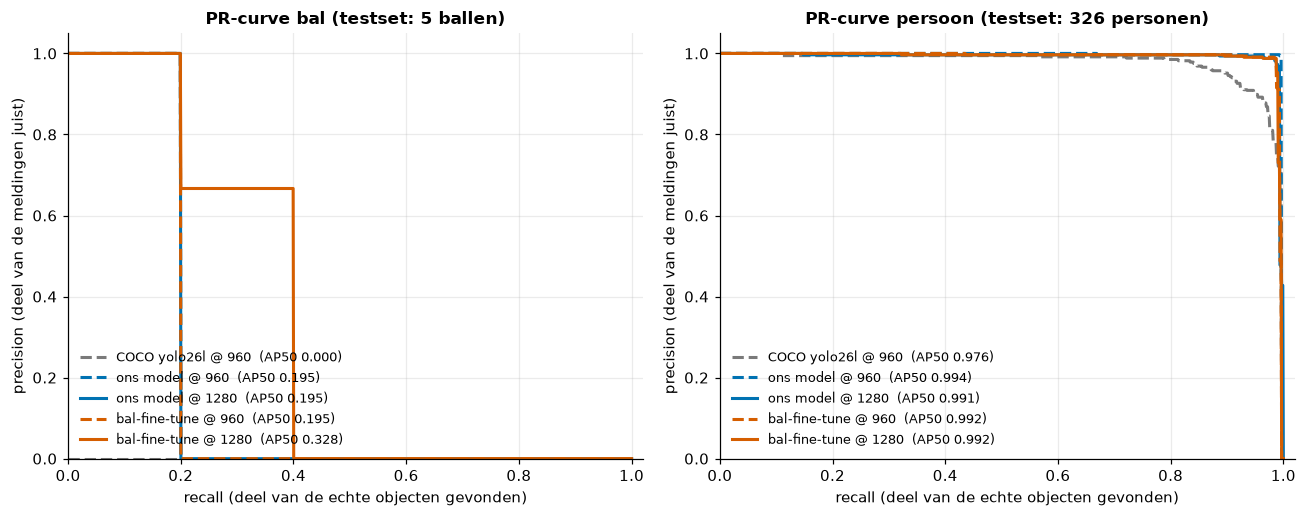

In [3]:
metrics = pd.read_csv(RES / "pr" / "metrics_all.csv")
metrics["model_nl"] = metrics["model"].map(MODEL_OF_CSV)


def curves(run, view):
    return np.load(RES / "pr" / f"curves_{run}_{view}.npz")


def ap50(model_csv, view, cls):
    r = metrics[(metrics.model == model_csv) & (metrics.view == view) & (metrics["class"] == cls)]
    return float(r["mAP50"].iloc[0])


CSV_NAME = {"COCO_yolo26l": "COCO yolo26l", "bestpt": "best.pt", "bestpt_1280": "best.pt@1280",
            "ball-finetune": "ball-finetune", "ball-finetune_1280": "ball-finetune@1280"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, cls in zip(axes, ["ball", "person"]):
    for run, (model, size) in RUNS.items():
        c = curves(run, "merged")
        ax.plot(c[f"{cls}__px"], c[f"{cls}__prec"], color=MODEL_COLOR[model], ls=SIZE_STYLE[size],
                label=f"{model} @ {size}  (AP50 {ap50(CSV_NAME[run], 'merged', cls):.3f})")
    ax.set(xlim=(0, 1.02), ylim=(0, 1.05), xlabel="recall (deel van de echte objecten gevonden)",
           ylabel="precision (deel van de meldingen juist)")
    n = int(metrics[(metrics.view == "merged") & (metrics["class"] == cls)]["instances"].iloc[0])
    ax.set_title(f"PR-curve {CLASS_NL[cls]} (testset: {n} {'ballen' if cls == 'ball' else 'personen'})")
    ax.legend(loc="lower left", fontsize=8.5)
plt.tight_layout()
plt.show()

**Wat zien we?**

- **Bal (links).** Het COCO-model vindt geen enkele van de 5 ballen: zijn curve ligt op recall 0 (AP50 0,000). Ons model
  vindt er met hoge zekerheid één (recall 0,2 bij precision 1) en daarna valt de curve naar 0: de andere 4 ballen
  krijgen bij geen enkele drempel een box die minstens 0,5 met het label overlapt. De curve springt in stappen van 0,2 omdat er
  maar 5 ballen zijn. Alleen de bal-fine-tune op 1280 haalt een tweede bal (recall 0,4, AP50 0,328): dat is **één bal
  meer**, statistisch heel zwak.
- **Persoon (rechts).** Alle modellen vinden bijna alle personen. Ons model ligt dicht tegen de rechterbovenhoek (AP50
  0,994); de precision van COCO begint vanaf recall ±0,8 te zakken (AP50 0,976): om de laatste personen te vinden,
  moet je bij COCO ook veel valse meldingen meenemen.

In [4]:
merged = metrics[metrics.view == "merged"].copy()
tab = merged.pivot_table(index=["model_nl", "imgsz"], columns="class",
                         values=["precision", "recall", "mAP50", "mAP50-95"])
tab = tab.reindex(columns=pd.MultiIndex.from_product([["precision", "recall", "mAP50", "mAP50-95"], ["ball", "person"]]))
tab.columns = [f"{CLASS_NL[c]}: {m}" for m, c in tab.columns]
tab = tab[[c for cls in ["bal", "persoon"] for c in tab.columns if c.startswith(cls)]]
tab = tab.reset_index().rename(columns={"model_nl": "model", "imgsz": "imgsz (px)"})
show(tab)

model,imgsz (px),bal: precision,bal: recall,bal: mAP50,bal: mAP50-95,persoon: precision,persoon: recall,persoon: mAP50,persoon: mAP50-95
COCO yolo26l,960,1.000,0.000,0.000,0.000,0.943,0.906,0.976,0.669
bal-fine-tune,960,0.901,0.200,0.195,0.058,0.991,0.980,0.992,0.733
bal-fine-tune,1280,0.489,0.400,0.328,0.130,0.960,0.988,0.992,0.735
ons model,960,0.934,0.200,0.195,0.078,0.997,0.992,0.994,0.815
ons model,1280,0.854,0.200,0.195,0.117,0.988,0.975,0.991,0.783


De tabel geeft P en R bij de confidence met de hoogste gemiddelde F1 (zo rapporteert ultralytics); bij recall 0 meldt
ultralytics per afspraak precision 1, vandaar de 1,000 van COCO voor de bal. De duidelijkste winst van ons model op
personen zit in **mAP50-95: 0,815 tegenover 0,669**. Beide modellen vinden de personen, maar de boxen van ons model
liggen veel strakker op de spelers zoals wij ze gelabeld hebben. Op 1280 pixels daalt mAP50-95 van ons model iets
(0,783): het model is getraind op 960 en ziet de spelers op 1280 groter dan het gewend is.

### Per klasse (alleen onze modellen)

Met de 5 eigen klassen kunnen we ook zien hoe goed het model de **rol** herkent (PSG, Inter, keeper, scheidsrechter).

model,imgsz (px),klasse,objecten,precision,recall,mAP50,mAP50-95
bal-fine-tune,960,bal,5,0.924,0.200,0.195,0.058
bal-fine-tune,960,speler PSG (A),142,0.985,0.950,0.992,0.734
bal-fine-tune,960,speler Inter (B),149,0.991,0.987,0.991,0.736
bal-fine-tune,960,keeper Inter,15,0.982,1.000,0.995,0.713
bal-fine-tune,960,scheidsrechter,20,0.849,0.950,0.860,0.612
bal-fine-tune,960,alle,331,0.946,0.817,0.807,0.571
bal-fine-tune,1280,bal,5,0.493,0.400,0.328,0.130
bal-fine-tune,1280,speler PSG (A),142,0.966,0.972,0.991,0.754
bal-fine-tune,1280,speler Inter (B),149,0.960,0.987,0.990,0.726
bal-fine-tune,1280,keeper Inter,15,0.877,1.000,0.995,0.745


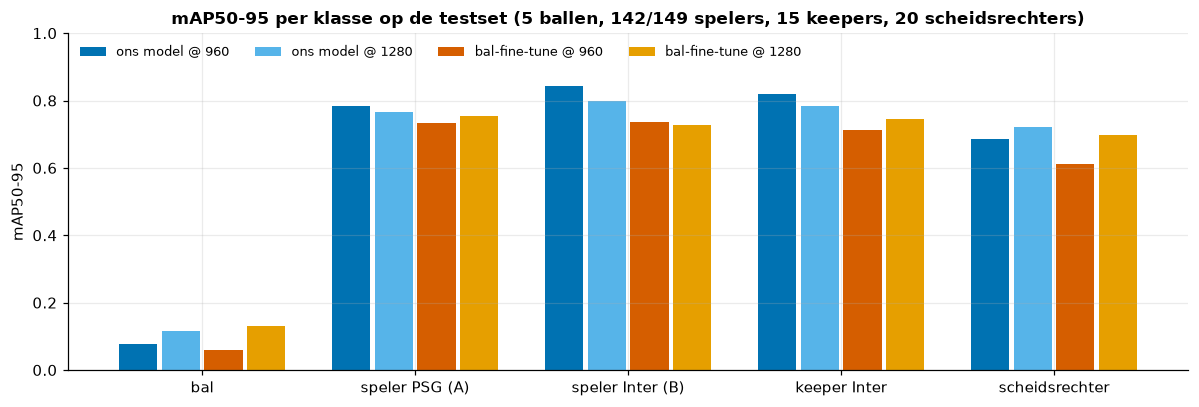

In [5]:
cls = metrics[metrics.view == "classes"].copy()
order = ["ball", "player_A", "player_B", "player_B_goal_keeper", "referee", "all"]
cls["klasse"] = cls["class"].map(CLASS_NL)
cls["_o"] = cls["class"].map(order.index)
tab = cls.sort_values(["model_nl", "imgsz", "_o"])[["model_nl", "imgsz", "klasse", "instances", "precision", "recall",
                                                    "mAP50", "mAP50-95"]]
show(tab.rename(columns={"model_nl": "model", "imgsz": "imgsz (px)", "instances": "objecten"}))

fig, ax = plt.subplots(figsize=(11, 3.8))
runs = [("best.pt", "ons model @ 960"), ("best.pt@1280", "ons model @ 1280"),
        ("ball-finetune", "bal-fine-tune @ 960"), ("ball-finetune@1280", "bal-fine-tune @ 1280")]
colors = ["#0072B2", "#56B4E9", "#D55E00", "#E69F00"]
classes = order[:-1]
w = 0.2
for k, ((name, label), color) in enumerate(zip(runs, colors)):
    vals = [float(cls[(cls.model == name) & (cls["class"] == c)]["mAP50-95"].iloc[0]) for c in classes]
    ax.bar(np.arange(len(classes)) + (k - 1.5) * w, vals, w * 0.9, color=color, label=label)
ax.set_xticks(range(len(classes)), [CLASS_NL[c] for c in classes])
ax.set(ylabel="mAP50-95", ylim=(0, 1), title="mAP50-95 per klasse op de testset (5 ballen, 142/149 spelers, 15 keepers, 20 scheidsrechters)")
ax.legend(ncol=4, fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.show()

**Wat zien we?** Spelers en keeper krijgen AP50 boven 0,99 en mAP50-95 rond 0,7–0,85; de scheidsrechter is iets
zwakker (AP50 0,94 voor ons model op 960), wat past bij de kleinere klasse (20 objecten). De bal is de zwakke plek bij
elk model: AP50 0,195, en mAP50-95 hooguit 0,13 (een box van een paar pixels ligt zelden heel precies op de bal). De
fine-tune scoort op de meeste personenklassen een lagere mAP50-95 dan ons model; dat komt terug in sectie 6.

### Confusion matrix

Een **confusion matrix** telt per echte klasse welke klasse het model voorspelde. Voor een detector komen er een extra
rij en kolom bij: een echt object zonder voorspelde box is **gemist**, een voorspelde box zonder echt object is een
**valse melding**. We berekenen hem hier zelf: ons model draait op de 15 testbeelden (dat duurt op de CPU enkele
seconden), met de drempels van de pijplijn (bal 0,2, personen 0,3), en elke voorspelde box wordt gekoppeld aan de
echte box waarmee hij het sterkst overlapt (IoU ≥ 0,5, hoogste confidence eerst, ongeacht de klasse). We doen het op
960 en op 1280.

15 testbeelden op 960 en 1280 voorspeld in 37 s (CPU)


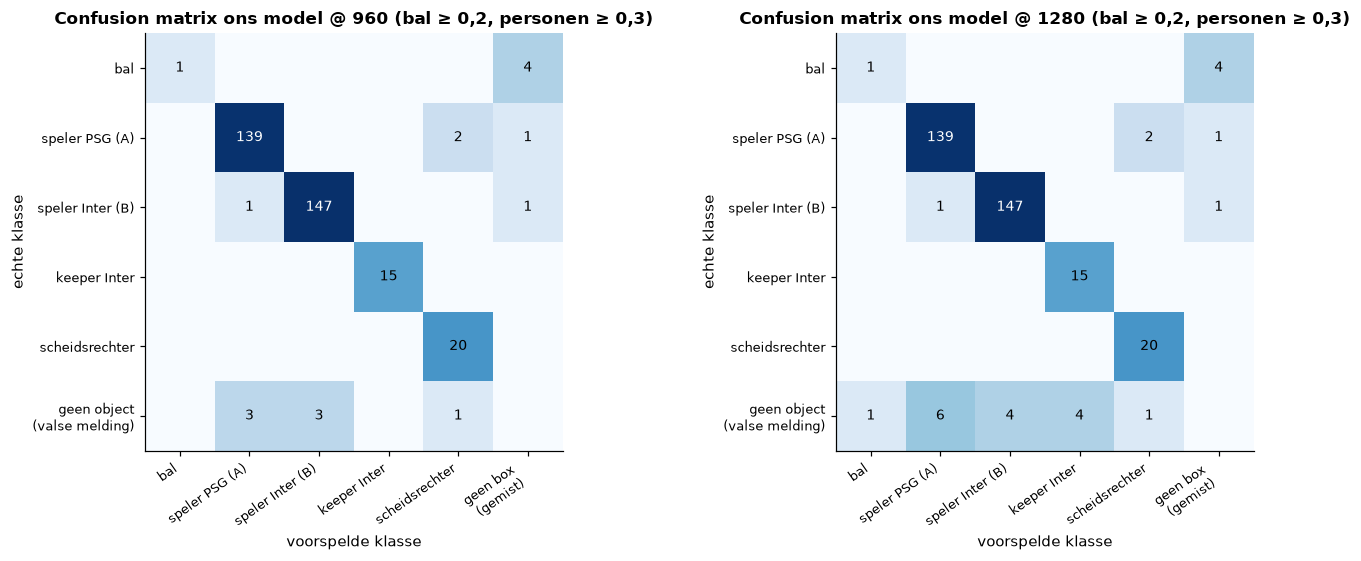

@ 960: bal juist 1/5, gemist 4, valse ballen 0; personen met juiste rol 321/324 gekoppelde, gemist 2, valse personen 7
@ 1280: bal juist 1/5, gemist 4, valse ballen 1; personen met juiste rol 321/324 gekoppelde, gemist 2, valse personen 15


In [6]:
from ultralytics import YOLO

NAMES = ["ball", "player_A", "player_B", "player_B_goal_keeper", "referee"]
CONF_OF = {0: pipe.DEFAULT_BALL_CONF, 1: 0.3, 2: 0.3, 3: 0.3, 4: 0.3}     # thresholds of the pipeline
test_imgs = sorted((DATASETS / "notebook_split" / "test" / "images").iterdir())


def iou_matrix(a, b):
    # IoU between every box in a (n,4) and b (m,4), boxes as x1 y1 x2 y2
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)


def labels_of(img, w, h):
    rows = np.loadtxt(img.parent.parent / "labels" / f"{img.stem}.txt", ndmin=2)
    cls, (cx, cy, bw, bh) = rows[:, 0].astype(int), rows[:, 1:].T
    return cls, np.stack([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h], 1)


def confusion(model, imgsz):
    n = len(NAMES)
    cm = np.zeros((n + 1, n + 1), int)            # rows: true class + "no object"; cols: predicted + "missed"
    for r in model.predict([str(p) for p in test_imgs], imgsz=imgsz, conf=DETECT_CONF, iou=0.7, verbose=False, device="cpu"):
        pc, pb, pconf = r.boxes.cls.numpy().astype(int), r.boxes.xyxy.numpy(), r.boxes.conf.numpy()
        keep = pconf >= np.array([CONF_OF[c] for c in pc])
        pc, pb, pconf = pc[keep], pb[keep], pconf[keep]
        h, w = r.orig_shape
        tc, tb = labels_of(Path(r.path), w, h)
        ious = iou_matrix(pb, tb) if len(pb) and len(tb) else np.zeros((len(pb), len(tb)))
        used = set()
        for i in np.argsort(-pconf):
            cand = [j for j in np.argsort(-ious[i]) if ious[i, j] >= 0.5 and j not in used]
            if cand:
                used.add(cand[0]); cm[tc[cand[0]], pc[i]] += 1
            else:
                cm[n, pc[i]] += 1                  # false detection
        for j in set(range(len(tc))) - used:
            cm[tc[j], n] += 1                      # missed object
    return cm


t0 = time.time()
model = YOLO(str(DEFAULT_WEIGHTS))
cms = {s: confusion(model, s) for s in (960, 1280)}
print(f"15 testbeelden op 960 en 1280 voorspeld in {time.time() - t0:.0f} s (CPU)")

labels_t = [CLASS_NL[c] for c in NAMES] + ["geen object\n(valse melding)"]
labels_p = [CLASS_NL[c] for c in NAMES] + ["geen box\n(gemist)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (s, cm) in zip(axes, cms.items()):
    ax.imshow(np.log1p(cm), cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                        color="white" if cm[i, j] > 40 else "black")
    ax.set_xticks(range(len(labels_p)), labels_p, rotation=35, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(labels_t)), labels_t, fontsize=8.5)
    ax.set(xlabel="voorspelde klasse", ylabel="echte klasse", title=f"Confusion matrix ons model @ {s} (bal ≥ 0,2, personen ≥ 0,3)")
    ax.grid(False)
plt.tight_layout()
plt.show()
for s, cm in cms.items():
    persons = cm[1:5, 1:5]
    print(f"@ {s}: bal juist {cm[0, 0]}/5, gemist {cm[0, 5]}, valse ballen {cm[5, 0]}; personen met juiste rol "
          f"{np.trace(persons)}/{persons.sum()} gekoppelde, gemist {cm[1:5, 5].sum()}, valse personen {cm[5, 1:5].sum()}")

**Wat zien we?** Bijna alles staat op de diagonaal. Van de 324 gekoppelde personen krijgen er 321 de juiste rol
(twee PSG-spelers worden scheidsrechter genoemd, één Inter-speler PSG); slechts 2 personen worden gemist. De bal is ook
hier de zwakke plek: 1 van de 5 ballen gevonden, 4 gemist (zelfde beeld als de recall 0,2 hierboven). Op 1280 verandert
er aan de juiste detecties niets, maar komen er meer valse meldingen bij (15 valse personen in plaats van 7, en 1 valse
bal): het model ziet op 1280 beelden die groter zijn dan het gewend is. Dat past bij de iets lagere mAP50-95 op 1280. In
de pijplijn vangt de tracker zulke losse valse boxen grotendeels op (sectie 5).

Ultralytics tekent zelf ook een confusion matrix (`data/results/gpu_run/pr/*/confusion_matrix.png`), maar bij andere,
vaste drempels (conf 0,25, IoU 0,45) en met een eigen manier van tellen; die gebruiken we hier niet.

## 3. De confidence-drempel kiezen

Een PR-curve vat alle drempels samen, maar in de praktijk moet je **één** drempel per klasse kiezen. Een veelgebruikt
criterium is de drempel met de hoogste **F1** (het harmonisch gemiddelde van precision en recall,
`F1 = 2·P·R / (P + R)`): daar zijn missers en valse meldingen in evenwicht. Het GPU-script koos per klasse de confidence
met de hoogste F1, na het afvlakken van de F1-curve over 5 % van de as (de ruwe curve piekt vaak vlak voor een klif,
waar één detectie meer of minder alles verandert).

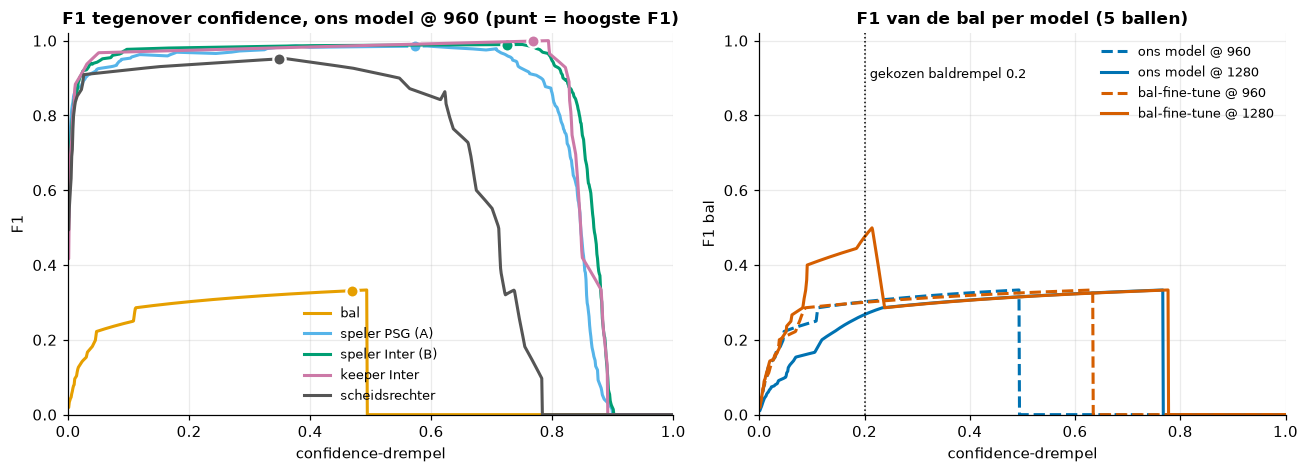

model,klasse,drempel (max F1),f1,precision,recall
ons model @ 960,bal,0.468,0.331,0.967,0.200
ons model @ 960,speler PSG (A),0.573,0.985,0.992,0.979
ons model @ 960,speler Inter (B),0.726,0.990,0.993,0.987
ons model @ 960,keeper Inter,0.769,0.999,0.998,1.000
ons model @ 960,scheidsrechter,0.348,0.951,0.907,1.000
bal-fine-tune @ 960,bal,0.609,0.332,0.977,0.200
bal-fine-tune @ 960,speler PSG (A),0.421,0.978,0.985,0.972
bal-fine-tune @ 960,speler Inter (B),0.644,0.990,0.993,0.987
bal-fine-tune @ 960,keeper Inter,0.731,0.999,0.998,1.000
bal-fine-tune @ 960,scheidsrechter,0.581,0.901,0.857,0.950


In [7]:
thr = pd.read_csv(RES / "thresholds" / "thresholds.csv")
c = curves("bestpt", "classes")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for k in ["ball", "player_A", "player_B", "player_B_goal_keeper", "referee"]:
    ax.plot(c[f"{k}__px"], c[f"{k}__f1"], color=CLASS_COLOR[k], label=CLASS_NL[k])
    t = thr[(thr.model == "best.pt") & (thr.view == "classes") & (thr["class"] == k)].iloc[0]
    ax.plot(t.best_conf, t.f1, "o", ms=8, color=CLASS_COLOR[k], mec="white", mew=1.5)
ax.set(xlabel="confidence-drempel", ylabel="F1", ylim=(0, 1.02), xlim=(0, 1),
       title="F1 tegenover confidence, ons model @ 960 (punt = hoogste F1)")
ax.legend(fontsize=8.5, loc="lower center")

ax = axes[1]
for run, (model, size) in RUNS.items():
    if model == "COCO yolo26l":
        continue
    cc = curves(run, "classes")
    ax.plot(cc["ball__px"], cc["ball__f1"], color=MODEL_COLOR[model], ls=SIZE_STYLE[size], label=f"{model} @ {size}")
ax.axvline(pipe.DEFAULT_BALL_CONF, color="black", lw=1, ls=":")
ax.text(pipe.DEFAULT_BALL_CONF + 0.01, 0.9, f"gekozen baldrempel {pipe.DEFAULT_BALL_CONF}", fontsize=8.5)
ax.set(xlabel="confidence-drempel", ylabel="F1 bal", ylim=(0, 1.02), xlim=(0, 1), title="F1 van de bal per model (5 ballen)")
ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout()
plt.show()

t = thr[thr.view == "classes"].copy()
t["model"] = t["model"].map(lambda m: f"{MODEL_OF_CSV[m]} @ {1280 if '1280' in m else 960}")
t["klasse"] = t["class"].map(CLASS_NL)
show(t[["model", "klasse", "best_conf", "f1", "precision", "recall"]].rename(columns={"best_conf": "drempel (max F1)"}))

**Wat zien we?**

- Voor **spelers en keeper** is de F1-curve een breed plateau: tussen ongeveer 0,1 en 0,7 blijft F1 boven 0,95. De
  scheidsrechter piekt lager (0,95 bij 0,35) en zakt al vanaf ±0,4. De exacte drempel maakt voor personen dus weinig
  uit, zolang hij niet te hoog ligt; de pijplijn start een persoonstrack vanaf confidence 0,3 en laat zwakkere
  boxen (vanaf 0,1) een bestaande track verderzetten (ByteTrack-principe).
- Voor de **bal** is de curve een trap: F1 0,33 zodra die ene bal gevonden wordt, en nooit hoger (behalve de fine-tune op
  1280, die de tweede bal vindt bij confidence ±0,2). Het "optimum" van 0,47 voor ons model ligt gewoon ergens op die
  trap. Met 5 ballen is dat statistisch geen keuze maar toeval.

### Waarom krijgt de bal een lagere drempel dan de spelers?

1. **De bal is klein (±15 pixels in het originele beeld) en vaak half verborgen**, dus het model is er minder zeker
   van: de meeste baldetecties in de clip hebben een confidence onder 0,3 en bijna geen enkele boven 0,7, terwijl
   personen meestal tussen 0,7 en 0,8 zitten (zie de histogrammen in sectie 5). Een drempel van 0,47 gooit veel echte
   ballen weg.
2. **Een gemiste bal kost meer dan een valse.** Er is maar één bal; als hij ontbreekt, is er geen balpositie en geen
   balbezit. Een losse valse bal wordt grotendeels opgevangen door de tracker: een nieuwe baltrack start pas bij
   confidence ≥ 0,25, en een kandidaat moet in de buurt van de voorspelde positie liggen (notebook 04).
3. De drempel werd daarom niet gekozen op de 5 testballen, maar op de **hele pijplijn tegen de ground truth**
   (sectie 7). Daar bleek 0,2 de beste afweging.

De drempels in de pijplijn op een rij:

In [8]:
show(pd.DataFrame([
    ("YOLO-detectie (cache)", DETECT_CONF, "YOLO draait één keer op deze lage drempel; alle echte drempels komen erna"),
    ("baldrempel (ball_conf)", pipe.DEFAULT_BALL_CONF, "kandidaat-bal moet minstens deze confidence hebben"),
    ("nieuwe baltrack starten", BALL_START_CONF, "zwakkere ballen kunnen alleen een bestaande track verderzetten"),
    ("persoonstrack starten (conf)", 0.3, "standaard van pipeline.run"),
    ("persoonstrack verderzetten", TRACK_LOW_THRESH, "tweede ronde van ByteTrack"),
], columns=["drempel", "waarde", "betekenis"]), digits=2)

drempel,waarde,betekenis
YOLO-detectie (cache),0.05,YOLO draait één keer op deze lage drempel; alle echte drempels komen erna
baldrempel (ball_conf),0.20,kandidaat-bal moet minstens deze confidence hebben
nieuwe baltrack starten,0.25,zwakkere ballen kunnen alleen een bestaande track verderzetten
persoonstrack starten (conf),0.30,standaard van pipeline.run
persoonstrack verderzetten,0.10,tweede ronde van ByteTrack


## 4. NMS en de IoU-drempel

Een objectdetector voorspelt rond hetzelfde object vaak **meerdere** licht verschoven boxen. **Non-maximum suppression
(NMS)** ruimt die op: sorteer de boxen op confidence, houd de beste, en verwijder elke andere box van dezelfde klasse die
er met een IoU boven een drempel mee overlapt. Een **lage** IoU-drempel verwijdert veel (ook twee echte spelers die
elkaar overlappen); een **hoge** drempel laat dubbele boxen staan.

YOLO26 heeft twee uitgangen (koppen): de klassieke *one-to-many*-kop, die per object meerdere kandidaten geeft en NMS
nodig heeft, en een *one-to-one*-kop die getraind is om per object maar één box te geven en dus **NMS-vrij** werkt. In
ultralytics 8.4.182 gebruikt ons model standaard de one-to-many-kop **met** NMS (IoU 0,7); met `nms=False` schakelt het
over op de NMS-vrije kop, en dan doet de IoU-drempel niets.

Het GPU-script deed `val()` van ons model (960) bij IoU 0,3 tot 0,8 en met `nms=False`:

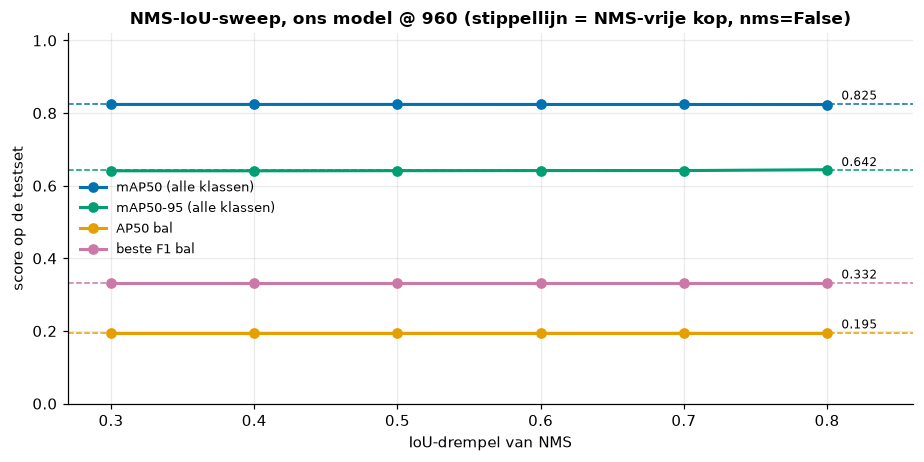

setting,mAP50,mAP50-95,AP50_ball,AP50_referee,bestF1_ball,bestF1_referee
NMS iou=0.3,0.824,0.641,0.195,0.942,0.331,0.951
NMS iou=0.4,0.824,0.641,0.195,0.942,0.331,0.951
NMS iou=0.5,0.824,0.641,0.195,0.942,0.331,0.951
NMS iou=0.6,0.824,0.642,0.195,0.942,0.331,0.951
NMS iou=0.7,0.824,0.642,0.195,0.942,0.331,0.951
NMS iou=0.8,0.823,0.644,0.195,0.942,0.331,0.951
nms=False (NMS-vrij),0.825,0.642,0.195,0.949,0.332,0.914


In [9]:
sweep = pd.read_csv(RES / "nms" / "sweep_val.csv")
nms_rows = sweep[sweep.nms == "ja"]
free = sweep[sweep.nms == "False"].iloc[0]
fig, ax = plt.subplots(figsize=(8.5, 4.3))
series = [("mAP50", "mAP50 (alle klassen)", "#0072B2"), ("mAP50-95", "mAP50-95 (alle klassen)", "#009E73"),
          ("AP50_ball", "AP50 bal", "#E69F00"), ("bestF1_ball", "beste F1 bal", "#CC79A7")]
for key, label, color in series:
    ax.plot(nms_rows.iou, nms_rows[key], "o-", color=color, label=label, ms=6)
    ax.axhline(free[key], color=color, ls="--", lw=1)
    ax.text(0.81, free[key] + 0.012, f"{free[key]:.3f}", color="black", fontsize=8)
ax.set(xlabel="IoU-drempel van NMS", ylabel="score op de testset", ylim=(0, 1.02), xlim=(0.27, 0.86),
       title="NMS-IoU-sweep, ons model @ 960 (stippellijn = NMS-vrije kop, nms=False)")
ax.legend(fontsize=8.5, loc="center left")
plt.tight_layout()
plt.show()
show(sweep[["setting", "mAP50", "mAP50-95", "AP50_ball", "AP50_referee", "bestF1_ball", "bestF1_referee"]])

**Wat zien we?** Niets, en dat is het resultaat: mAP50 blijft tussen 0,823 en 0,825 voor elke IoU-drempel en ook voor de
NMS-vrije kop; de bal blijft op AP50 0,195. Alleen de scheidsrechter beweegt een beetje met de NMS-vrije kop (AP50 0,949
tegenover 0,942, maar beste F1 0,914 tegenover 0,951).

**Waarom geen effect?** Een IoU-drempel verandert alleen iets voor boxen van dezelfde klasse die elkaar overlappen. Op de
testset gaat het daarbij bijna altijd om boxen met een lage confidence. Die belanden onderaan de gesorteerde lijst en
bepalen alleen het staartje van de PR-curve, waar de precision al laag is; de AP verandert daardoor nauwelijks. Hoeveel
boxen het werkelijk scheelt, zien we in de detectiecaches van de hele clip (ons model @ 960):

instelling,min. confidence,boxen per frame (gem.),boxen in de clip
"NMS IoU 0,7 (standaard)",0.05,28.51,18819
"NMS IoU 0,7 (standaard)",0.30,24.80,16371
"NMS IoU 0,5",0.05,25.37,16747
"NMS IoU 0,5",0.30,23.99,15832
NMS-vrij (nms=False),0.05,33.33,22000
NMS-vrij (nms=False),0.30,24.94,16460


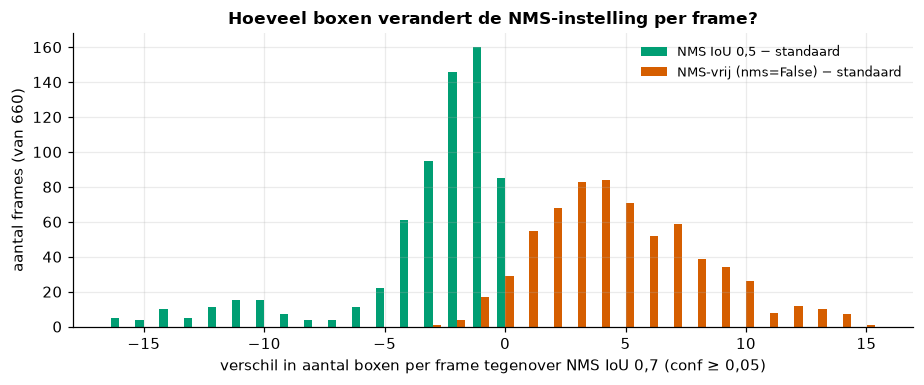

In [10]:
def load_cache(weights, imgsz, iou=0.7, nms=None):
    p = cache_path(VIDEO, weights, imgsz, iou, 0, LAST_FRAME, 1, nms=nms)
    assert p.exists(), f"cache missing (would start YOLO): {p.name}"
    return {f["frame"]: f["detections"] for f in json.loads(p.read_text(encoding="utf-8"))["frames"]}


nms_caches = {"NMS IoU 0,7 (standaard)": load_cache(DEFAULT_WEIGHTS, 960, 0.7),
              "NMS IoU 0,5": load_cache(DEFAULT_WEIGHTS, 960, 0.5),
              "NMS-vrij (nms=False)": load_cache(DEFAULT_WEIGHTS, 960, 0.7, nms=False)}
rows = []
for name, det in nms_caches.items():
    for min_conf in (0.05, 0.3):
        n = np.array([sum(d["conf"] >= min_conf for d in det[i]) for i in range(LAST_FRAME + 1)])
        rows.append({"instelling": name, "min. confidence": min_conf, "boxen per frame (gem.)": n.mean(),
                     "boxen in de clip": int(n.sum())})
counts = pd.DataFrame(rows)
show(counts, digits=2)

base = np.array([len(nms_caches["NMS IoU 0,7 (standaard)"][i]) for i in range(LAST_FRAME + 1)])
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for (name, det), color in zip(list(nms_caches.items())[1:], ["#009E73", "#D55E00"]):
    diff = np.array([len(det[i]) for i in range(LAST_FRAME + 1)]) - base
    vals, cnt = np.unique(diff, return_counts=True)
    off = -0.18 if color == "#009E73" else 0.18
    ax.bar(vals + off, cnt, 0.34, color=color, label=f"{name} − standaard")
ax.set(xlabel="verschil in aantal boxen per frame tegenover NMS IoU 0,7 (conf ≥ 0,05)", ylabel="aantal frames (van 660)",
       title="Hoeveel boxen verandert de NMS-instelling per frame?")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

**Wat zien we?** IoU 0,5 in plaats van 0,7 verwijdert in de meeste frames 1 tot 4 boxen (in enkele drukke frames tot
16), gemiddeld 3,1 per frame bij confidence ≥ 0,05 maar slechts 0,8 per frame bij confidence ≥ 0,3. De NMS-vrije kop
geeft juist **meer** boxen (gemiddeld +4,8 per frame), maar bij confidence ≥ 0,3 is dat verschil bijna weg (+0,1). Het
gaat dus vooral om zwakke boxen. De pijplijn gebruikt zwakke persoonsboxen alleen om bestaande tracks verder te zetten,
en verwijdert zelf nog eens persoonsboxen die meer dan 0,6 overlappen (dubbele detecties). Daardoor verandert de
NMS-instelling weinig aan het eindresultaat.

### Effect op de hele pijplijn

Het GPU-script draaide de hele clip ook door de pijplijn met de standaard en de twee "beste" andere instellingen uit de
sweep. Hieronder rekenen we dat opnieuw uit de caches en vergelijken met `pipeline_effect.csv`.

In [11]:
def pipeline_eval(weights, imgsz, ball_conf=0.1, iou=0.7, nms=None):
    # Whole clip through the app pipeline (from the detection cache, never YOLO) + evaluation against both GT files.
    assert cache_path(VIDEO, weights, imgsz, iou, 0, LAST_FRAME, 1, nms=nms).exists(), "no cache: would start YOLO"
    r = pipe.run(weights=weights, imgsz=imgsz, ball_conf=ball_conf, iou=iou, nms=nms)
    with tempfile.TemporaryDirectory() as tmp:
        tr = pipe.save_tracks_csv(r, Path(tmp) / "tracks.csv")
        fr = pipe.save_frames_csv(r, Path(tmp) / "frames.csv")
        people, ball, poss = load_predictions(tr, fr)
    states = [r.ball[i]["state"] if i in r.ball else "none" for i in r.ids]
    out = {"ball_detected": states.count("detected"), "ball_interpolated": states.count("interpolated"),
           "ball_none": states.count("none"), "possession_A_pct": pipe.possession_share(r).get("A", 0.0)}
    found = false = n_with = n_without = 0
    for anchor, gt in (("body", gt_body), ("feet", gt_feet)):
        res = evaluate(gt, people, ball, poss, anchor=anchor)
        b = res["ball"]
        f, fa = round(b["detection_rate"] * b["frames_with_ball"]), round(b["false_ball_rate"] * b["frames_without_ball"])
        out.update({f"{anchor}_found": f, f"{anchor}_false": fa, f"{anchor}_players_f1": res["players"]["f1"],
                    f"{anchor}_role_acc": res["teams"]["role_accuracy"], f"{anchor}_possession_acc": res["possession"]["accuracy"]})
        found, false, n_with, n_without = found + f, false + fa, n_with + b["frames_with_ball"], n_without + b["frames_without_ball"]
    out.update({"gt_found": found, "gt_with_ball": n_with, "gt_false": false, "gt_without_ball": n_without,
                "_states": states})
    return out


effect = pd.read_csv(RES / "pipeline_effect.csv")
effect["model_nl"] = effect["model"].map(MODEL_OF_CSV)
for a in ("body", "feet"):
    effect[[f"_{a}_found", f"_{a}_n"]] = effect[f"{a}_ball_found"].str.split("/", expand=True).astype(int)
    effect[[f"_{a}_false", f"_{a}_m"]] = effect[f"{a}_false_ball"].str.split("/", expand=True).astype(int)
effect["GT-ballen gevonden"] = effect._body_found + effect._feet_found
effect["valse ballen"] = effect._body_false + effect._feet_false

t0 = time.time()
check = []
for _, row in effect.iterrows():
    w = DEFAULT_WEIGHTS if row.model_nl == "ons model" else FT_WEIGHTS
    nms = False if "nms=False" in row.setting else None
    iou = 0.5 if "iou=0.5" in row.setting else 0.7
    mine = pipeline_eval(w, int(row.imgsz), 0.1, iou, nms)       # the GPU run used ball_conf 0.1 (the old default)
    same = (mine["ball_none"] == row.ball_none and mine["gt_found"] == row["GT-ballen gevonden"]
            and mine["gt_false"] == row["valse ballen"] and mine["ball_detected"] == row.ball_detected)
    check.append(same)
effect["opnieuw berekend = GPU-run"] = check
print(f"{len(effect)} pijplijnruns opnieuw berekend uit de cache in {time.time() - t0:.0f} s; "
      f"alle gelijk aan pipeline_effect.csv: {all(check)}")

6 pijplijnruns opnieuw berekend uit de cache in 16 s; alle gelijk aan pipeline_effect.csv: True


In [12]:
nms_tab = effect[(effect.model_nl == "ons model") & (effect.imgsz == 960)]
cols = {"setting": "instelling", "ball_detected": "bal gedetecteerd", "ball_interpolated": "bal ingevuld",
        "ball_none": "geen bal", "GT-ballen gevonden": "GT-ballen gevonden (/21)", "valse ballen": "valse ballen (/7)",
        "body_players_f1": "spelers F1", "body_role_acc": "juiste rol", "body_possession_acc": "balbezit juist (lichaam)",
        "possession_A_pct": "balbezit PSG (%)"}
show(nms_tab[list(cols)].rename(columns=cols))

instelling,bal gedetecteerd,bal ingevuld,geen bal,GT-ballen gevonden (/21),valse ballen (/7),spelers F1,juiste rol,balbezit juist (lichaam),balbezit PSG (%)
NMS iou=0.7,332,136,192,16,5,0.986,0.990,0.773,100.000
nms=False (NMS-vrij),322,163,175,16,4,0.977,0.971,0.682,91.071
NMS iou=0.5,332,136,192,16,5,0.988,0.977,0.773,100.000


**Wat zien we?** IoU 0,5 en 0,7 geven exact hetzelfde balverloop (332 frames gedetecteerd, 192 zonder bal) en bijna
dezelfde spelerscores. De NMS-vrije kop vult wat meer frames met een bal en meldt één valse bal minder, maar de juiste
rol (0,971 tegenover 0,990) en vooral het juiste balbezit op de lichaam-ground-truth (0,68 tegenover 0,77) worden
slechter. Er is dus geen reden om van de standaard af te wijken: **NMS met IoU 0,7 blijft**. (De kolommen "bal ingevuld"
en "geen bal" tellen frames van de hele clip; zie notebook 04 voor hoe de tracker gaten invult.)

## 5. Beeldgrootte: 960 tegenover 1280 pixels

YOLO schaalt elk frame (1920×1080) naar een vaste grootte (`imgsz`, de langste zijde) voor het door het netwerk gaat.
Ons model is getraind op 960. Op 960 wordt het frame dus met factor 2 verkleind, en een bal van ±15 pixels in het
origineel (gemeten hieronder) wordt ±7 pixels: na de eerste downsampling-lagen van het netwerk (die het beeld telkens
halveren) blijft daar weinig van over. Op 1280 is de
verkleining kleiner (factor 1,5). Groter dan de trainingsgrootte werken mag: het netwerk is convolutioneel, al ziet het
de objecten dan groter dan tijdens de training. De prijs is rekentijd: op de CPU detecteert 1280 ongeveer twee keer
trager dan 960 (daarom komen de detecties hier uit de cache van de GPU-run).

Eerst kijken we in de caches van de hele clip naar de ruwe baldetecties van ons model op beide groottes.

Grootte van een baldetectie (conf ≥ 0,2) in het originele frame: mediaan 15 px (10e–90e percentiel 12–19 px)


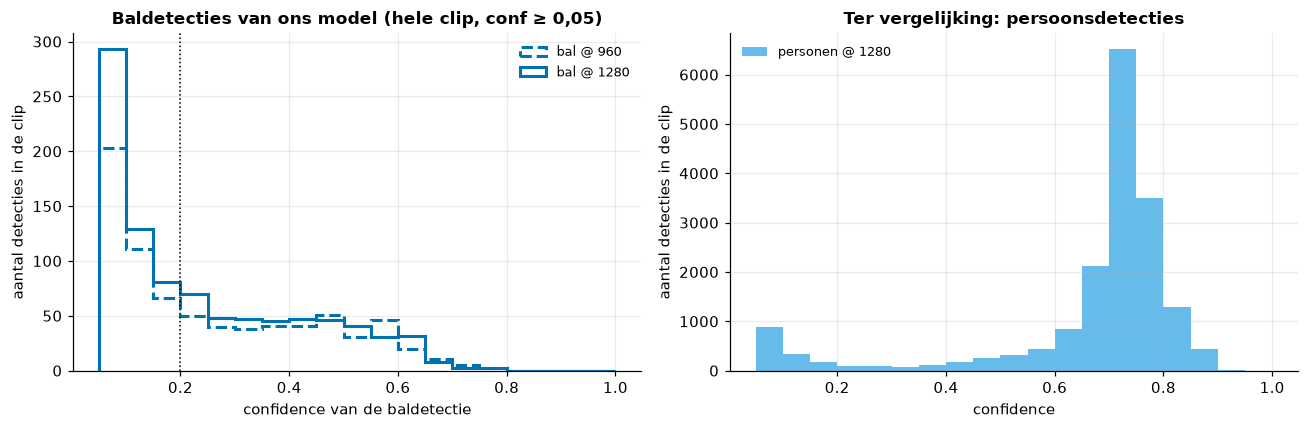

imgsz,"baldetecties (conf ≥ 0,05)","frames met een bal ≥ 0,1","frames met een bal ≥ 0,2","frames met een bal ≥ 0,4"
960,756,361,285,183
1280,922,406,328,195


In [13]:
det960, det1280 = load_cache(DEFAULT_WEIGHTS, 960), load_cache(DEFAULT_WEIGHTS, 1280)


def ball_dets(det):
    return [d for i in range(LAST_FRAME + 1) for d in det[i] if d["name"] == "ball"]


b960, b1280 = ball_dets(det960), ball_dets(det1280)
size = [max(d["box"][2] - d["box"][0], d["box"][3] - d["box"][1]) for d in b960 + b1280 if d["conf"] >= 0.2]
pers = [d["conf"] for i in range(LAST_FRAME + 1) for d in det1280[i] if d["name"] != "ball"]
print(f"Grootte van een baldetectie (conf ≥ 0,2) in het originele frame: mediaan {np.median(size):.0f} px "
      f"(10e–90e percentiel {np.percentile(size, 10):.0f}–{np.percentile(size, 90):.0f} px)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0.05, 1, 20)
ax = axes[0]
ax.hist([d["conf"] for d in b960], bins=bins, histtype="step", lw=2, ls="--", color=MODEL_COLOR["ons model"], label="bal @ 960")
ax.hist([d["conf"] for d in b1280], bins=bins, histtype="step", lw=2, color=MODEL_COLOR["ons model"], label="bal @ 1280")
ax.axvline(pipe.DEFAULT_BALL_CONF, color="black", lw=1, ls=":")
ax.set(xlabel="confidence van de baldetectie", ylabel="aantal detecties in de clip",
       title="Baldetecties van ons model (hele clip, conf ≥ 0,05)")
ax.legend(fontsize=8.5)
ax = axes[1]
ax.hist(pers, bins=bins, color="#56B4E9", alpha=0.9, label="personen @ 1280")
ax.set(xlabel="confidence", ylabel="aantal detecties in de clip", title="Ter vergelijking: persoonsdetecties")
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

frames_with = lambda det, c: sum(any(d["name"] == "ball" and d["conf"] >= c for d in det[i]) for i in range(LAST_FRAME + 1))
show(pd.DataFrame([{"imgsz": s, "baldetecties (conf ≥ 0,05)": len(b),
                    "frames met een bal ≥ 0,1": frames_with(det, 0.1), "frames met een bal ≥ 0,2": frames_with(det, 0.2),
                    "frames met een bal ≥ 0,4": frames_with(det, 0.4)}
                   for s, b, det in [(960, b960, det960), (1280, b1280, det1280)]]))

**Wat zien we?** Een gedetecteerde bal is in het originele beeld ±15 pixels groot (12–19 px); ballen die het model
helemaal niet vindt, zijn wellicht nog kleiner of half verborgen. Op 1280 vindt het model in meer frames een bal, bij
elke drempel (bv. 328 tegenover 285 frames bij confidence ≥ 0,2). Het grootste deel van de baldetecties heeft een lage
confidence (onder 0,3), terwijl personen meestal tussen 0,7 en 0,8 zitten. Dat is precies waarom de baldrempel laag
moet liggen (sectie 3).

### Het effect op de hele pijplijn

Nu de vraag die telt: wat doet 1280 met de balpositie in de minimap? We vergelijken de oude standaard (960, baldrempel
0,1) met 1280 bij baldrempel 0,1 en 0,2, gemeten op de 28 ground-truth-frames (21 met een zichtbare bal, 7 zonder) en
op de hele clip.

In [14]:
configs = [("960, baldrempel 0,1 (oude standaard)", DEFAULT_WEIGHTS, 960, 0.1),
           ("1280, baldrempel 0,1", DEFAULT_WEIGHTS, 1280, 0.1),
           ("1280, baldrempel 0,2 (nieuwe standaard)", DEFAULT_WEIGHTS, 1280, 0.2)]
size_runs = {name: pipeline_eval(w, s, c) for name, w, s, c in configs}
size_tab = pd.DataFrame([{"instelling": n, "GT-ballen gevonden": f"{r['gt_found']}/{r['gt_with_ball']}",
                          "valse ballen": f"{r['gt_false']}/{r['gt_without_ball']}",
                          "frames met gedetecteerde bal": r["ball_detected"], "frames met ingevulde bal": r["ball_interpolated"],
                          "frames zonder bal": r["ball_none"], "spelers F1 (lichaam)": r["body_players_f1"],
                          "juiste rol (lichaam)": r["body_role_acc"],
                          "balbezit juist (lichaam / voeten)": f"{r['body_possession_acc']:.2f} / {r['feet_possession_acc']:.2f}",
                          "balbezit PSG (%)": r["possession_A_pct"]} for n, r in size_runs.items()])
show(size_tab)

# The headline numbers must match the files of the GPU run (ball_conf 0.1) and the documented new default (0.2)
r960, r1280_01, r1280 = size_runs.values()
row960 = effect[(effect.model == "best.pt") & (effect.setting == "NMS iou=0.7") & (effect.imgsz == 960)].iloc[0]
row1280 = effect[(effect.model == "best.pt@1280")].iloc[0]
assert (r960["gt_found"], r960["ball_none"]) == (row960["GT-ballen gevonden"], row960.ball_none) == (16, 192)
assert (r1280_01["gt_found"], r1280_01["ball_none"]) == (row1280["GT-ballen gevonden"], row1280.ball_none) == (19, 130)
assert (r1280["gt_found"], r1280["gt_false"], r1280["ball_none"]) == (19, 5, 161)
print("Gecontroleerd: 960 -> 16/21 GT-ballen en 192 frames zonder bal; 1280 @ 0,2 -> 19/21 en 161 (5/7 valse ballen).")

instelling,GT-ballen gevonden,valse ballen,frames met gedetecteerde bal,frames met ingevulde bal,frames zonder bal,spelers F1 (lichaam),juiste rol (lichaam),balbezit juist (lichaam / voeten),balbezit PSG (%)
"960, baldrempel 0,1 (oude standaard)",16/21,5/7,332,136,192,0.986,0.990,0.77 / 0.67,100.000
"1280, baldrempel 0,1",19/21,5/7,364,166,130,0.986,0.992,0.77 / 0.67,88.292
"1280, baldrempel 0,2 (nieuwe standaard)",19/21,5/7,308,191,161,0.986,0.992,0.77 / 0.67,91.858


Gecontroleerd: 960 -> 16/21 GT-ballen en 192 frames zonder bal; 1280 @ 0,2 -> 19/21 en 161 (5/7 valse ballen).


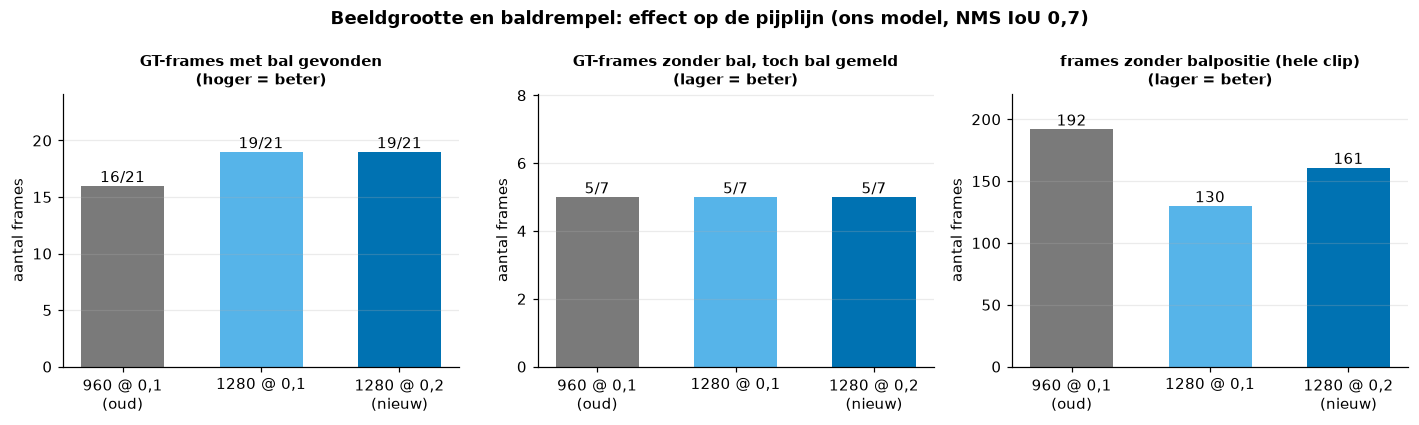

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
names = list(size_runs)
short = ["960 @ 0,1\n(oud)", "1280 @ 0,1", "1280 @ 0,2\n(nieuw)"]
colors = ["#7a7a7a", "#56B4E9", "#0072B2"]
panels = [("gt_found", "GT-frames met bal gevonden", 21, "hoger = beter"),
          ("gt_false", "GT-frames zonder bal, toch bal gemeld", 7, "lager = beter"),
          ("ball_none", "frames zonder balpositie (hele clip)", 660, "lager = beter")]
for ax, (key, title, total, hint) in zip(axes, panels):
    vals = [size_runs[n][key] for n in names]
    bars = ax.bar(short, vals, color=colors, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v}" + (f"/{total}" if total < 100 else ""), ha="center", va="bottom")
    ax.set_title(f"{title}\n({hint})", fontsize=10)
    ax.set_ylim(0, (total if total < 100 else max(vals)) * 1.15)
    ax.set_ylabel("aantal frames")
    ax.grid(axis="x", alpha=0)
fig.suptitle("Beeldgrootte en baldrempel: effect op de pijplijn (ons model, NMS IoU 0,7)", fontweight="bold")
plt.tight_layout()
plt.show()

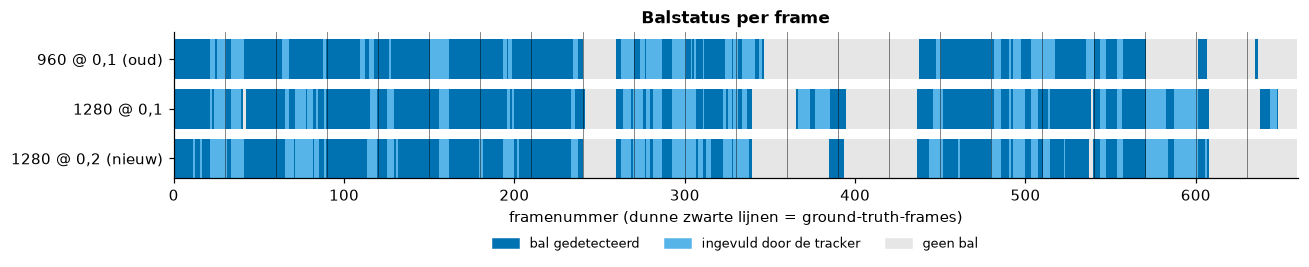

In [16]:
state_code = {"detected": 2, "interpolated": 1, "none": 0}
fig, ax = plt.subplots(figsize=(12, 2.8))
cmap ={2: "#0072B2", 1: "#56B4E9", 0: "#e6e6e6"}
for y, (name, lab) in enumerate(zip(names[::-1], [s.replace("\n", " ") for s in short[::-1]])):
    st = np.array([state_code[s] for s in size_runs[name]["_states"]])
    for v in (2, 1, 0):
        xs = np.where(st == v)[0]
        ax.bar(xs, 0.8, width=1.0, bottom=y - 0.4, color=cmap[v], linewidth=0)
ax.set_yticks(range(len(names)), [s.replace("\n", " ") for s in short[::-1]])
for x in sorted(set(gt_frames)):
    ax.axvline(x, color="black", lw=0.6, alpha=0.5)
from matplotlib.patches import Patch
ax.set(xlim=(0, 660), xlabel="framenummer (dunne zwarte lijnen = ground-truth-frames)", title="Balstatus per frame")
ax.legend(handles=[Patch(color=cmap[2], label="bal gedetecteerd"), Patch(color=cmap[1], label="ingevuld door de tracker"),
                   Patch(color=cmap[0], label="geen bal")], ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32), fontsize=8.5)
ax.grid(alpha=0)
plt.tight_layout()
plt.show()

**Wat zien we?** Dit is de belangrijkste winst van de hele afstelling:

- **Van 16 naar 19 van de 21** ground-truth-frames met een zichtbare bal krijgen een balpositie, met evenveel valse
  ballen (5 van 7 frames waarop de bal niet zichtbaar is, krijgen er toch een; dat is vooral de tracker die de laatst
  bekende positie doortrekt, zie notebook 04).
- Het aantal frames **zonder bal** in de hele clip daalt van **192 naar 161** (−16 %). In de tijdlijn zie je waar: rond
  frames 380–395 en 570–610 heeft 1280 een bal waar 960 er geen heeft.
- Spelers, rollen en balbezitnauwkeurigheid blijven gelijk (F1 ±0,99, rol ±0,99, balbezit 0,77 / 0,67). Het aandeel
  balbezit verschuift wel: op 960 krijgt PSG 100 % van het balbezit, op 1280 ook een stuk voor Inter.

**Waarom baldrempel 0,2 en niet 0,1 op 1280?** Met 0,1 heeft 1280 nog minder frames zonder bal (130), maar op 1280 komen
er ook **stilliggende valse ballen** met lage confidence bij (in de projectnotities: frames 366–376, confidence
0,11–0,14, visueel nagekeken). Die trekken de interpolatie naar een verkeerde plek. Baldrempel 0,2 haalt ze weg en
houdt de 19/21. Sectie 7 bekijkt de drempel systematisch.

## 6. De bal-fine-tune: opzet, verloop en waarom hij niet gebruikt wordt

Omdat de bal de zwakke plek is, probeerden we ons model **verder te trainen** (fine-tunen) met de nadruk op de bal.

**Opzet** (uit `finetune.json`, `finetune/train_1280_b4/args.yaml` en `log.txt`):

| Instelling | Waarde | Waarom |
|---|---|---|
| startgewichten | ons model (`best.pt`) | voortbouwen op wat het al kan |
| beeldgrootte | 1280 | de bal is op 960 maar ±7 px groot (sectie 5) |
| klassengewichten | `cls_pw 0.5` | gewicht per klasse = (1 / frequentie)^0,5, genormaliseerd: de zeldzame bal weegt zwaarder in de klasse-loss |
| data | de 100 frames van de oudere export (v2), **per tijdsblok** gesplitst: train = frames < 200 en 246–599, val = 200–245, frames ≥ 600 (testset) weggelaten | buurframes lijken bijna identiek; een willekeurige split zou ze over train en val verdelen |
| epochs | max. 60, early stopping met patience 15 | stoppen zodra de validatie 15 epochs niet meer verbetert |
| overig | batch 4, seed 0, deterministic, cosine-leersnelheid, mosaic uit voor de laatste 10 epochs | reproduceerbaar |

In [17]:
ft = json.loads((RES / "finetune.json").read_text(encoding="utf-8"))
log = (RES / "log.txt").read_text(encoding="utf-8", errors="replace")
opt_line = next(l for l in log.splitlines() if "AdamW(" in l or "SGD(" in l)
cw_line = next(l for l in log.splitlines() if l.startswith("Class weights"))
stop_line = next(l for l in log.splitlines() if "Best results observed" in l)
clean = lambda s: re.sub(r"\x1b\[[0-9;]*m", "", s).strip()
print("Optimizer      :", clean(opt_line))
print("Klassengewicht :", clean(cw_line), " (volgorde: ball, player_A, player_B, keeper, referee)")
print("Early stopping :", clean(stop_line))
print(f"Data           : {len(ft_train)} trainings- en {len(ft_val)} validatiebeelden; overlap met de testset: "
      f"{ft['overlap']['n_overlap']}/{ft['overlap']['n_test']}")
print(f"Epochs gedraaid: {ft['epochs_run']} (beste epoch {ft['best_epoch']}), duur {ft['seconds'] / 60:.1f} min")

Optimizer      : optimizer: AdamW(lr=0.001111, momentum=0.9) with parameter groups 178 weight(decay=0.0), 190 weight(decay=0.0005), 190 bias(decay=0.0)
Klassengewicht : Class weights: [      1.723       0.465       0.469       1.484       0.859]  (volgorde: ball, player_A, player_B, keeper, referee)
Early stopping : EarlyStopping: Training stopped early as no improvement observed in last 15 epochs. Best results observed at epoch 1, best model saved as best.pt.
Data           : 59 trainings- en 26 validatiebeelden; overlap met de testset: 0/15
Epochs gedraaid: 16 (beste epoch 1), duur 23.6 min


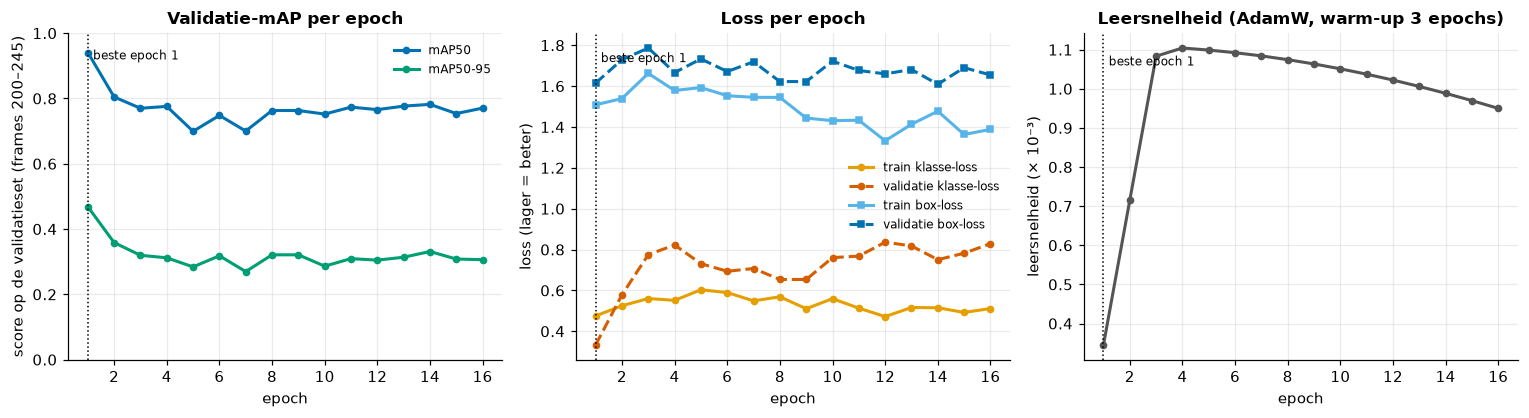

epoch,precision,recall,mAP50,mAP50-95,val/cls_loss,lr/pg0
1,0.9481,0.9133,0.9407,0.4684,0.3338,0.0003
2,0.8607,0.6919,0.8046,0.3585,0.5783,0.0007
3,0.8598,0.6078,0.7700,0.3197,0.7750,0.0011
4,0.8775,0.6922,0.7757,0.3119,0.8224,0.0011
5,0.4664,0.8052,0.6994,0.2841,0.7308,0.0011
6,0.6827,0.7747,0.7480,0.3181,0.6937,0.0011
7,0.6971,0.7390,0.7001,0.2697,0.7072,0.0011
8,0.8121,0.7544,0.7631,0.3211,0.6535,0.0011
9,0.8121,0.7544,0.7631,0.3211,0.6535,0.0011
10,0.8205,0.7141,0.7521,0.2864,0.7604,0.0011


In [18]:
res = pd.read_csv(RES / "finetune" / "train_1280_b4" / "results.csv")
res.columns = [c.strip() for c in res.columns]
best = int(res.loc[res["metrics/mAP50(B)"].idxmax(), "epoch"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
ax.plot(res.epoch, res["metrics/mAP50(B)"], "o-", color="#0072B2", ms=4, label="mAP50")
ax.plot(res.epoch, res["metrics/mAP50-95(B)"], "o-", color="#009E73", ms=4, label="mAP50-95")
ax.set(xlabel="epoch", ylabel="score op de validatieset (frames 200–245)", ylim=(0, 1), title="Validatie-mAP per epoch")
ax = axes[1]
ax.plot(res.epoch, res["train/cls_loss"], "o-", color="#E69F00", ms=4, label="train klasse-loss")
ax.plot(res.epoch, res["val/cls_loss"], "o--", color="#D55E00", ms=4, label="validatie klasse-loss")
ax.plot(res.epoch, res["train/box_loss"], "s-", color="#56B4E9", ms=4, label="train box-loss")
ax.plot(res.epoch, res["val/box_loss"], "s--", color="#0072B2", ms=4, label="validatie box-loss")
ax.set(xlabel="epoch", ylabel="loss (lager = beter)", title="Loss per epoch")
ax = axes[2]
ax.plot(res.epoch, res["lr/pg0"] * 1000, "o-", color="#555555", ms=4)
ax.set(xlabel="epoch", ylabel="leersnelheid (× 10⁻³)", title="Leersnelheid (AdamW, warm-up 3 epochs)")
for a in axes:
    a.axvline(best, color="black", ls=":", lw=1)
    a.text(best + 0.2, a.get_ylim()[1] * 0.95, f"beste epoch {best}", fontsize=8, va="top")
for a in axes[:2]:
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()
show(res[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)", "val/cls_loss",
          "lr/pg0"]].rename(columns=lambda c: c.replace("metrics/", "").replace("(B)", "")), digits=4)

**Wat zien we? Waarom mislukte de fine-tune?**

- De beste validatiescore komt al na **epoch 1** (mAP50 0,941, mAP50-95 0,468). Daarna zakt mAP50 naar 0,70–0,80 en
  stijgt de validatie-klasse-loss van 0,33 naar 0,58–0,84, terwijl de train-loss nauwelijks daalt (box-loss 1,51 →
  1,39, klasse-loss blijft rond 0,5). Na 15 epochs zonder
  verbetering stopte early stopping de training bij epoch 16. Het opgeslagen model (`best_ball_ft.pt`) is dus het model
  na één epoch.
- De leersnelheid loopt tijdens de warm-up op van 0,00035 (epoch 1) naar 0,0011 (epoch 3–4) en blijft daarna rond
  0,001. **Precies wanneer de leersnelheid stijgt, gaat het model achteruit.** Het model was al goed getraind; met deze
  leersnelheid worden de gewichten zo sterk aangepast dat het model een deel van wat het kon "vergeet", in plaats van
  bij te leren. Voor fine-tunen van een al getraind model gebruik je een kleinere leersnelheid en eventueel bevroren
  eerste lagen (`freeze`).
- Een correctie op de projectnotities: daar staat dat lr0 = 0,01 te hoog was. Het script zette wel `lr0=0.01`, maar met
  `optimizer=auto` negeert ultralytics die waarde en kiest het zelf AdamW met leersnelheid 0,001111 (zie de
  logregel hierboven). De conclusie "te hoge leersnelheid voor fine-tunen" blijft, maar de werkelijke waarde was ±0,0011.
  Een volgende poging zou de optimizer en een lagere leersnelheid expliciet vastzetten (bv. `optimizer="AdamW",
  lr0=0.0001`, `freeze=10`); dat is niet meer getest.
- De hoge score na epoch 1 is zelf ook te rooskleurig: de validatiebeelden (frames 200–245) zaten in de
  trainingsdata van het startmodel (sectie 1). Het startmodel kende ze al.
- Er zijn ook maar 59 trainingsbeelden met elk ongeveer één bal: weinig om iets nieuws over de bal te leren.

### Ons model tegenover de fine-tune

Op de testset (sectie 2) scoorde de fine-tune op 1280 één bal meer (bal-AP50 0,328 tegenover 0,195), maar hij verloor
mAP50-95 op personen (0,735 tegenover 0,815 voor ons model op 960). De beslissende vergelijking is de pijplijn:

model,GT-ballen gevonden (/21),valse ballen (/7),frames zonder bal,spelers F1,juiste rol,balbezit juist (lichaam),balbezit juist (voeten)
ons model @ 960,16,5,192,0.986,0.990,0.773,0.667
bal-fine-tune @ 960,16,5,210,0.984,0.998,0.727,0.667
bal-fine-tune @ 1280,19,5,137,0.984,0.992,0.773,0.667
ons model @ 1280,19,5,130,0.986,0.992,0.773,0.667


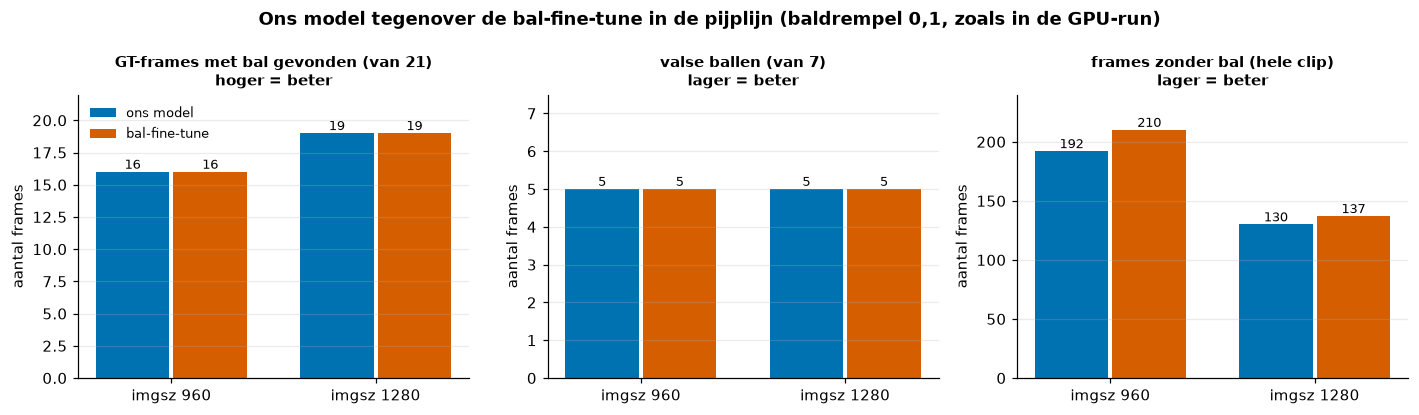

In [19]:
cmp = effect[effect.setting == "NMS iou=0.7"].copy()
cmp["model"] = cmp.model_nl + " @ " + cmp.imgsz.astype(str)
cols = {"model": "model", "GT-ballen gevonden": "GT-ballen gevonden (/21)", "valse ballen": "valse ballen (/7)",
        "ball_none": "frames zonder bal", "body_players_f1": "spelers F1", "body_role_acc": "juiste rol",
        "body_possession_acc": "balbezit juist (lichaam)", "feet_possession_acc": "balbezit juist (voeten)"}
show(cmp[list(cols)].rename(columns=cols))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("GT-ballen gevonden", "GT-frames met bal gevonden (van 21)\nhoger = beter", 22),
          ("valse ballen", "valse ballen (van 7)\nlager = beter", 7.5),
          ("ball_none", "frames zonder bal (hele clip)\nlager = beter", 240)]
for ax, (key, title, top) in zip(axes, panels):
    for k, m in enumerate(["ons model", "bal-fine-tune"]):
        sub = cmp[cmp.model_nl == m].set_index("imgsz")
        vals = [sub.loc[960, key], sub.loc[1280, key]]
        bars = ax.bar(np.arange(2) + (k - 0.5) * 0.38, vals, 0.36, color=MODEL_COLOR[m], label=m)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, str(int(v)), ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(range(2), ["imgsz 960", "imgsz 1280"])
    ax.set(ylabel="aantal frames", title=title, ylim=(0, top))
    ax.title.set_fontsize(10)
    ax.grid(axis="x", alpha=0)
axes[0].legend(fontsize=8.5, loc="upper left")
fig.suptitle("Ons model tegenover de bal-fine-tune in de pijplijn (baldrempel 0,1, zoals in de GPU-run)", fontweight="bold")
plt.tight_layout()
plt.show()

**Wat zien we?** Op 960 is de fine-tune gelijk of slechter (evenveel ballen gevonden, meer frames zonder bal: 210
tegenover 192). Op 1280 vinden beide modellen 19 van de 21 ballen met 5 valse ballen; de fine-tune heeft zelfs iets meer
frames zonder bal (137 tegenover 130). De winst die de fine-tune op de testset leek te hebben, is dus vooral de winst van
**1280 pixels**, en die krijgt ons oorspronkelijke model ook zonder extra training. Daarom wordt `best_ball_ft.pt`
**niet** gebruikt; het staat alleen ter vergelijking in `models/experimenten/`.

## 7. De baldrempel systematisch variëren

Omdat de pijplijn uit de cache in een paar seconden draait, kunnen we de baldrempel (`ball_conf`) over een heel bereik
variëren, voor ons model op 960 en 1280 en voor de fine-tune op 1280, en telkens meten tegen de ground truth. Dit is de
pijplijnversie van een precision-recall-afweging: een hogere drempel geeft minder valse ballen maar ook minder gevonden
ballen. Drempels onder 0,05 hebben geen zin: YOLO draaide op 0,05.

27 pijplijnruns in 79 s (uit de cache, zonder YOLO)


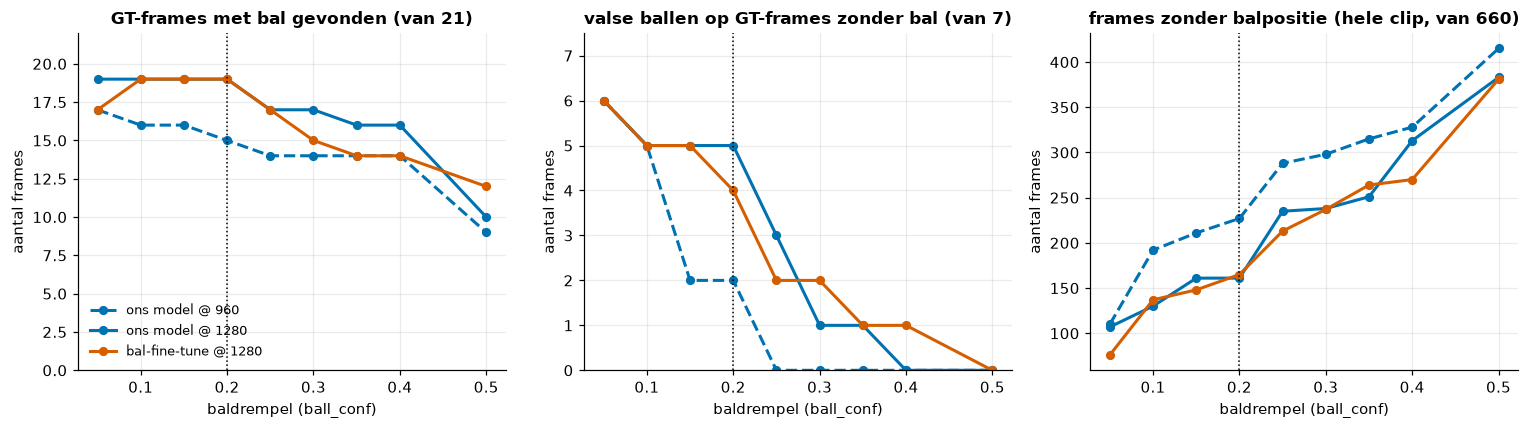

In [20]:
grid = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
sweep_cfg = [("ons model", 960, DEFAULT_WEIGHTS), ("ons model", 1280, DEFAULT_WEIGHTS), ("bal-fine-tune", 1280, FT_WEIGHTS)]
t0 = time.time()
rows = []
for model, size, w in sweep_cfg:
    for c in grid:
        r = pipeline_eval(w, size, c)
        rows.append({"model": model, "imgsz": size, "baldrempel": c, "GT-ballen gevonden": r["gt_found"],
                     "valse ballen": r["gt_false"], "frames zonder bal": r["ball_none"],
                     "balbezit juist (lichaam)": r["body_possession_acc"]})
conf_sweep = pd.DataFrame(rows)
print(f"{len(rows)} pijplijnruns in {time.time() - t0:.0f} s (uit de cache, zonder YOLO)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (key, title, ylim) in zip(axes, [("GT-ballen gevonden", "GT-frames met bal gevonden (van 21)", (0, 22)),
                                         ("valse ballen", "valse ballen op GT-frames zonder bal (van 7)", (0, 7.5)),
                                         ("frames zonder bal", "frames zonder balpositie (hele clip, van 660)", None)]):
    for model, size, _ in sweep_cfg:
        s = conf_sweep[(conf_sweep.model == model) & (conf_sweep.imgsz == size)]
        ax.plot(s.baldrempel, s[key], "o", ls=SIZE_STYLE[size], color=MODEL_COLOR[model], ms=5, label=f"{model} @ {size}")
    ax.axvline(pipe.DEFAULT_BALL_CONF, color="black", lw=1, ls=":")
    ax.set(xlabel="baldrempel (ball_conf)", ylabel="aantal frames", title=title)
    if ylim:
        ax.set_ylim(*ylim)
axes[0].legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()
show(conf_sweep.pivot_table(index="baldrempel", columns=["model", "imgsz"],
                            values=["GT-ballen gevonden", "valse ballen", "frames zonder bal"]).reset_index(), digits=2)

**Wat zien we?**

- Op **1280** vindt ons model bij elke drempel meer ballen dan op 960 (bv. 19 tegenover 15 bij 0,2). Hoe hoger de
  drempel, hoe minder valse ballen maar ook hoe minder gevonden ballen: de klassieke precision-recall-afweging, nu op
  het niveau van de hele pijplijn. Vanaf 0,3 meldt 1280 nog hoogstens één valse bal, maar vindt het nog maar 17 of
  minder ballen.
- Het aantal frames zonder bal stijgt met de drempel. Tussen 0,1 en 0,2 kost dat op 1280 31 frames (130 → 161), maar
  zoals in sectie 5 uitgelegd zijn dat deels frames met een stilliggende valse bal; op de ground truth verandert er
  niets (19/21, 5/7). 0,15 en 0,2 geven op 1280 exact hetzelfde resultaat.
- **0,2** is het hoogste punt dat nog 19 van de 21 ballen vindt; bij 0,25 gaan er al 2 verloren. 0,3 is de
  "precisie-keuze" (17/21 gevonden, 1/7 vals). Met 21 + 7 frames blijft dit een kleine meting: één frame verschil is
  al zichtbaar in de grafiek.
- Op 960 daalt het aantal valse ballen sneller (2/7 vanaf 0,15), maar daar vindt de pijplijn ook minder ballen.
- De fine-tune op 1280 volgt ons model grotendeels; bij 0,2 meldt hij één valse bal minder (4/7) maar heeft hij ook
  4 frames meer zonder bal (165). Zulke verschillen van één frame zijn geen reden om een model te kiezen dat op de
  personen slechter scoort en waarvan de training mislukte.

## 8. Conclusies

1. **Ons model is beter dan het COCO-basismodel.** COCO vindt de bal niet (AP50 0,000 tegenover 0,195) en omkadert
   personen minder nauwkeurig (mAP50-95 0,669 tegenover 0,815). Fine-tunen op eigen gelabelde frames is dus nodig, vooral
   voor de bal en om de rollen (PSG, Inter, keeper, scheidsrechter) te onderscheiden.
2. **De NMS-IoU-drempel doet er voor ons model niet toe** (mAP50 0,823–0,825 voor IoU 0,3–0,8 en voor de NMS-vrije kop).
   De NMS-vrije kop gaf in de pijplijn slechtere rollen en balbezit. Standaard: NMS met IoU 0,7.
3. **Inferentie op 1280 in plaats van 960 is de grootste winst**: 19 in plaats van 16 van de 21 ground-truth-ballen
   gevonden, evenveel valse ballen (5/7), 161 in plaats van 192 frames zonder bal, spelers en balbezit gelijk. Kost: ±2×
   trager detecteren op de CPU.
4. **Baldrempel 0,2** (en niet de 0,47 uit de F1-curve, die op 5 testballen rust): laag genoeg om de kleine, onzekere bal
   te houden, hoog genoeg om stilliggende valse ballen met confidence 0,11–0,14 weg te halen. Spelers starten een track
   vanaf 0,3.
5. **De bal-fine-tune mislukte** (beste epoch 1 van 16, de leersnelheid van ±0,001 was te hoog voor verder trainen van een
   al getraind model) en geeft in de pijplijn geen winst tegenover ons model op 1280. Hij wordt niet gebruikt.

**Gekozen standaard** (in `streamlit/core/pipeline.py`: `DEFAULT_IMGSZ = 1280`, `DEFAULT_BALL_CONF = 0.2`): het
oorspronkelijke model `models/psg_vs_inter_CV.pt`, imgsz 1280, baldrempel 0,2, NMS-IoU 0,7.

## Beperkingen

- **Leakage in de testset.** Alle 15 testbeelden zaten in de trainingsdata van ons model; de validatiebeelden van de
  fine-tune ook. De detectiecijfers (niveau A) zijn te optimistisch en zeggen weinig over nieuwe beelden. Ook 7 van de 22
  ground-truth-frames zijn trainingsframes.
- **Heel kleine aantallen.** 5 ballen in de testset, 21 + 7 ground-truth-frames voor de bal. Eén bal verschil is al een
  grote stap; geen enkel verschil hier is statistisch getest.
- **De instellingen zijn gekozen op dezelfde ground truth waarop we ze rapporteren.** Er is geen aparte set om de
  gekozen drempel en beeldgrootte onafhankelijk te bevestigen; een deel van de winst kan dus "afgestemd op deze 28
  frames" zijn.
- **Eén clip van 22 seconden.** Andere camerahoeken, belichting of tenues zijn niet getest.
- **De fine-tune is één poging** met één set instellingen; een poging met een lagere, vastgezette leersnelheid en bevroren
  lagen is niet gedaan. Daaruit volgt niet dat fine-tunen voor de bal zinloos is.
- **Wat ontbreekt:** een eerlijke testset met nieuw gelabelde frames uit het middenstuk van de clip (ongeveer 63–199 en 246–524), weg van de trainingsframes. Het script om ze te
  exporteren staat klaar in `export_unseen_frames.py` (in de projectrepository onder `kobe/match_analyse/gpu/`).